# FIFA 22: estimación de la valoración de jugadores

**Hector Americo Torres Huamani** · [Repositorio](https://github.com/hectortorres26/fifa22-analisis-jugadores)

## 1. Contexto y objetivo

Estimar `value_eur`, la valoración asignada a los jugadores dentro de FIFA 22, a partir de doce atributos deportivos y físicos. El alcance es la estructura de valoración del videojuego; no el salario (`wage_eur`) ni el precio de un traspaso real.

## 2. Datos y reproducibilidad

[FIFA 22 Complete Player Dataset, publicado por Stefano Leone en Kaggle](https://www.kaggle.com/datasets/stefanoleone992/fifa-22-complete-player-dataset). Descarga `players_22.csv` y colócalo en `data/`. Se usa exclusivamente el archivo de jugadores de FIFA 22; no se mezclan otras ediciones.

Los resultados publicados se ejecutaron con copias públicas descargadas de las fuentes indicadas. No se ha verificado identidad byte a byte con los archivos del Drive del autor. Las huellas SHA-256 en [data/README.md](data/README.md) y `reports/metrics.json` identifican las entradas exactas. Los datasets se excluyen de Git; consulta las condiciones de cada fuente antes de reutilizarlos o redistribuirlos.

| Campo | Uso |
|---|---|
| `value_eur` | Objetivo, valoración del videojuego en EUR |
| `sofifa_id` | Control de unicidad; excluido del modelo |
| `age`, `height_cm`, `weight_kg` | Atributos físicos y edad |
| `overall`, `potential`, `international_reputation` | Valoraciones generales del juego |
| `pace`, `shooting`, `passing`, `dribbling`, `defending`, `physic` | Habilidades de campo; permiten nulos que se imputan en entrenamiento |
| `wage_eur`, `release_clause_eur` | Excluidos; pueden actuar como aproximaciones del objetivo |

Ejecuta desde la raíz del repositorio con el entorno de `requirements.txt`. El código de análisis reside en `src/analysis.py`, para que el cuaderno y la línea de comandos utilicen el mismo procedimiento.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from src.analysis import run

ROOT = Path.cwd()
assert (ROOT / 'src/analysis.py').exists(), 'Abre el cuaderno desde la raíz del repositorio.'

## 3. Diseño del análisis

1. Validar unicidad de `sofifa_id`, esquema y valores numéricos. De 19.239 filas, excluir 74 sin valoración válida y positiva; nunca imputar la variable objetivo. Quedan 19.165 jugadores.
2. Utilizar doce atributos predefinidos; excluir identificadores, nombres, salario, cláusula de rescisión y la propia valoración de los predictores.
3. Reservar el 20 % como prueba aleatoria con semilla 42. Ajustar imputación por mediana e indicadores de ausencia dentro de cada partición.
4. Comparar referencia por mediana, Ridge con escalado y gradient boosting de histogramas. Los dos modelos entrenan sobre `log1p(value_eur)` y devuelven predicciones en EUR con `expm1`.
5. Seleccionar por MAE en EUR mediante cinco particiones del entrenamiento. Evaluar una vez el modelo seleccionado y la referencia en prueba.
6. Describir errores por rango de valor e importancia por permutación (cinco repeticiones) como diagnóstico posterior; no reutilizar ese diagnóstico para seleccionar variables. Calcular un intervalo de MAE con 500 remuestreos de los errores de prueba.

In [2]:
resultado = run(ROOT / 'data/players_22.csv', ROOT / 'reports')

## 4. Resultados calculados

Las tablas siguientes proceden de esta ejecución. Las métricas comparativas utilizan una prueba reservada cuando el proyecto entrena modelos.

In [3]:
display(pd.DataFrame({'Modelo': resultado['test'], 'Referencia': resultado['baseline_test']}))
display(pd.DataFrame([resultado['calidad']['nulos_features']]).T.rename(columns={0: 'Nulos antes de imputar'}))

,Modelo,Referencia
mae_eur,1.523356e+05,2.337478e+06
rmse_eur,1.259772e+06,8.131754e+06
r2,9.746636e-01,-5.567263e-02


,Nulos antes de imputar
age,0
height_cm,0
weight_kg,0
overall,0
potential,0
international_reputation,0
pace,2124
shooting,2124
passing,2124
dribbling,2124


### Validacion cruzada

In [4]:
display(pd.read_csv(ROOT / 'reports/validacion_cruzada.csv'))

,modelo,mae_cv_eur,desviacion_cv_eur
0,base_mediana,2.360054e+06,151165.905487
1,ridge_log,5.871047e+05,49076.662755
2,gradient_boosting_log,1.484596e+05,23815.579960


### Error por rango

In [5]:
display(pd.read_csv(ROOT / 'reports/error_por_rango.csv'))

,rango_valor,n,mae_eur
0,≤1 M€,2051,1.981572e+04
1,1–5 M€,1415,8.636974e+04
2,5–20 M€,267,4.808615e+05
3,>20 M€,100,2.926572e+06


### Importancia variables

In [6]:
display(pd.read_csv(ROOT / 'reports/importancia_variables.csv'))

,variable,incremento_mae_eur,desviacion
0,overall,2.410546e+06,18051.329034
1,potential,1.365384e+06,19885.821406
2,age,3.712261e+05,12617.074940
3,dribbling,6.323112e+04,2134.754654
4,pace,4.880296e+04,3834.502377
5,shooting,3.702673e+04,2532.364358
6,defending,1.569016e+04,630.273305
7,passing,1.360853e+03,246.516581
8,physic,1.195847e+03,276.336946
9,height_cm,6.154714e+01,159.941123


## 5. Visualización e interpretación

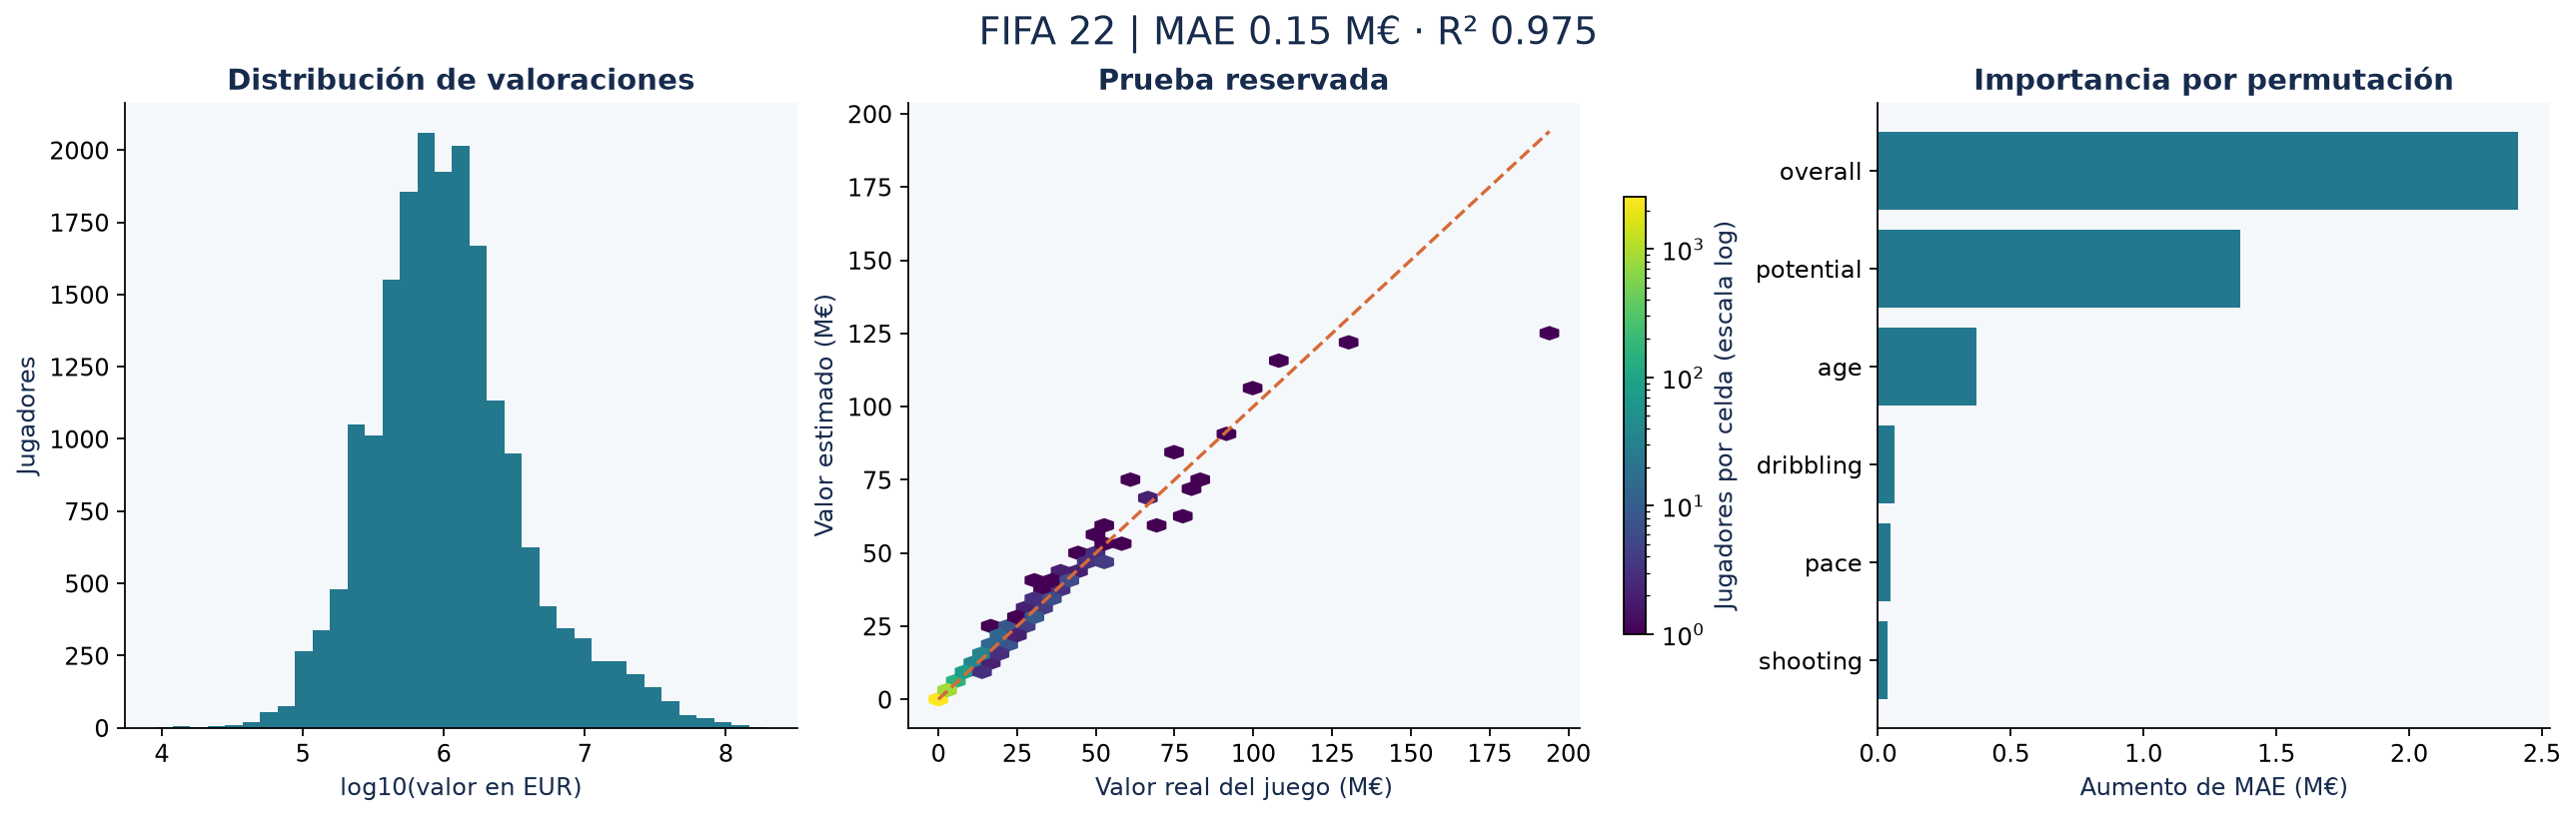

In [7]:
display(Image(filename=str(ROOT / 'reports/evaluacion.png')))

El modelo reproduce bien la estructura de valoración del juego. La diferencia entre RMSE y MAE muestra errores grandes en algunos jugadores: para los 100 jugadores de prueba valorados en más de 20 millones de EUR, el MAE es de 2,93 millones. `overall`, `potential` y `age` destacan en la importancia por permutación, consistente con una valoración del videojuego fuertemente vinculada a esos atributos. Esto no demuestra capacidad para valorar fichajes reales.

## 6. Limitaciones y próximos pasos

La validación aleatoria dentro de una misma edición no prueba generalización temporal a otras ediciones ni al mercado real. Las valoraciones pueden derivarse de reglas internas asociadas a los propios atributos, lo que facilita predicciones altas. Las seis habilidades de campo tienen 2.124 valores ausentes cada una en las filas retenidas; la imputación con indicadores no sustituye un estudio específico de porteros. La importancia por permutación depende de correlaciones entre atributos y no representa causalidad. El intervalo bootstrap mantiene fijo el modelo y no incorpora incertidumbre del entrenamiento. El modelo se entrena con pérdida sobre el objetivo logarítmico, aunque se selecciona y evalúa por error en EUR.

Antes de ampliar el uso, validar con una fuente independiente y acordar criterios de utilidad con el destinatario. Consulta el README para reproducir las pruebas y los informes.

## 7. Trazabilidad de esta ejecución

Se muestran nombres de archivos, huellas SHA-256 y versiones; las entradas completas permanecen fuera de Git.

In [8]:
fuentes = resultado.get('fuentes', [resultado.get('fuente')])
print(json.dumps(fuentes, ensure_ascii=False, indent=2))

[
  {
    "archivo": "players_22.csv",
    "sha256": "b82a9a932ef74729d05e95b6f72334e664711bf6326132d8c38f5912cfc41c3f",
    "python": "3.11.9",
    "paquetes": {
      "pandas": "3.0.6",
      "numpy": "2.4.6",
      "matplotlib": "3.11.2",
      "scikit-learn": "1.9.1"
    }
  }
]


[Historial del proyecto](https://github.com/hectortorres26/fifa22-analisis-jugadores/commits/main) · [Comparación con el original](https://github.com/hectortorres26/fifa22-analisis-jugadores/compare/420ad20f5aabeab2901a1270194053a5af660570...main)